# **PM to Redesign Recommendations - a pipeline prototype**

This prototype accepts event logs (.xes files) and generates a textual directly-follows graph, which will be used as input for LLM to recognize any bottleneck in the process and generate redesign recommendations.


## **1. Import the required libraries**

In [28]:
import export
import pm4py
import pandas
import requests
import json

from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI


## **2. Load the event log and generate DFG from it using PM4Py library**


parsing log, completed traces :: 100%|██████████| 5131/5131 [00:02<00:00, 2468.14it/s]


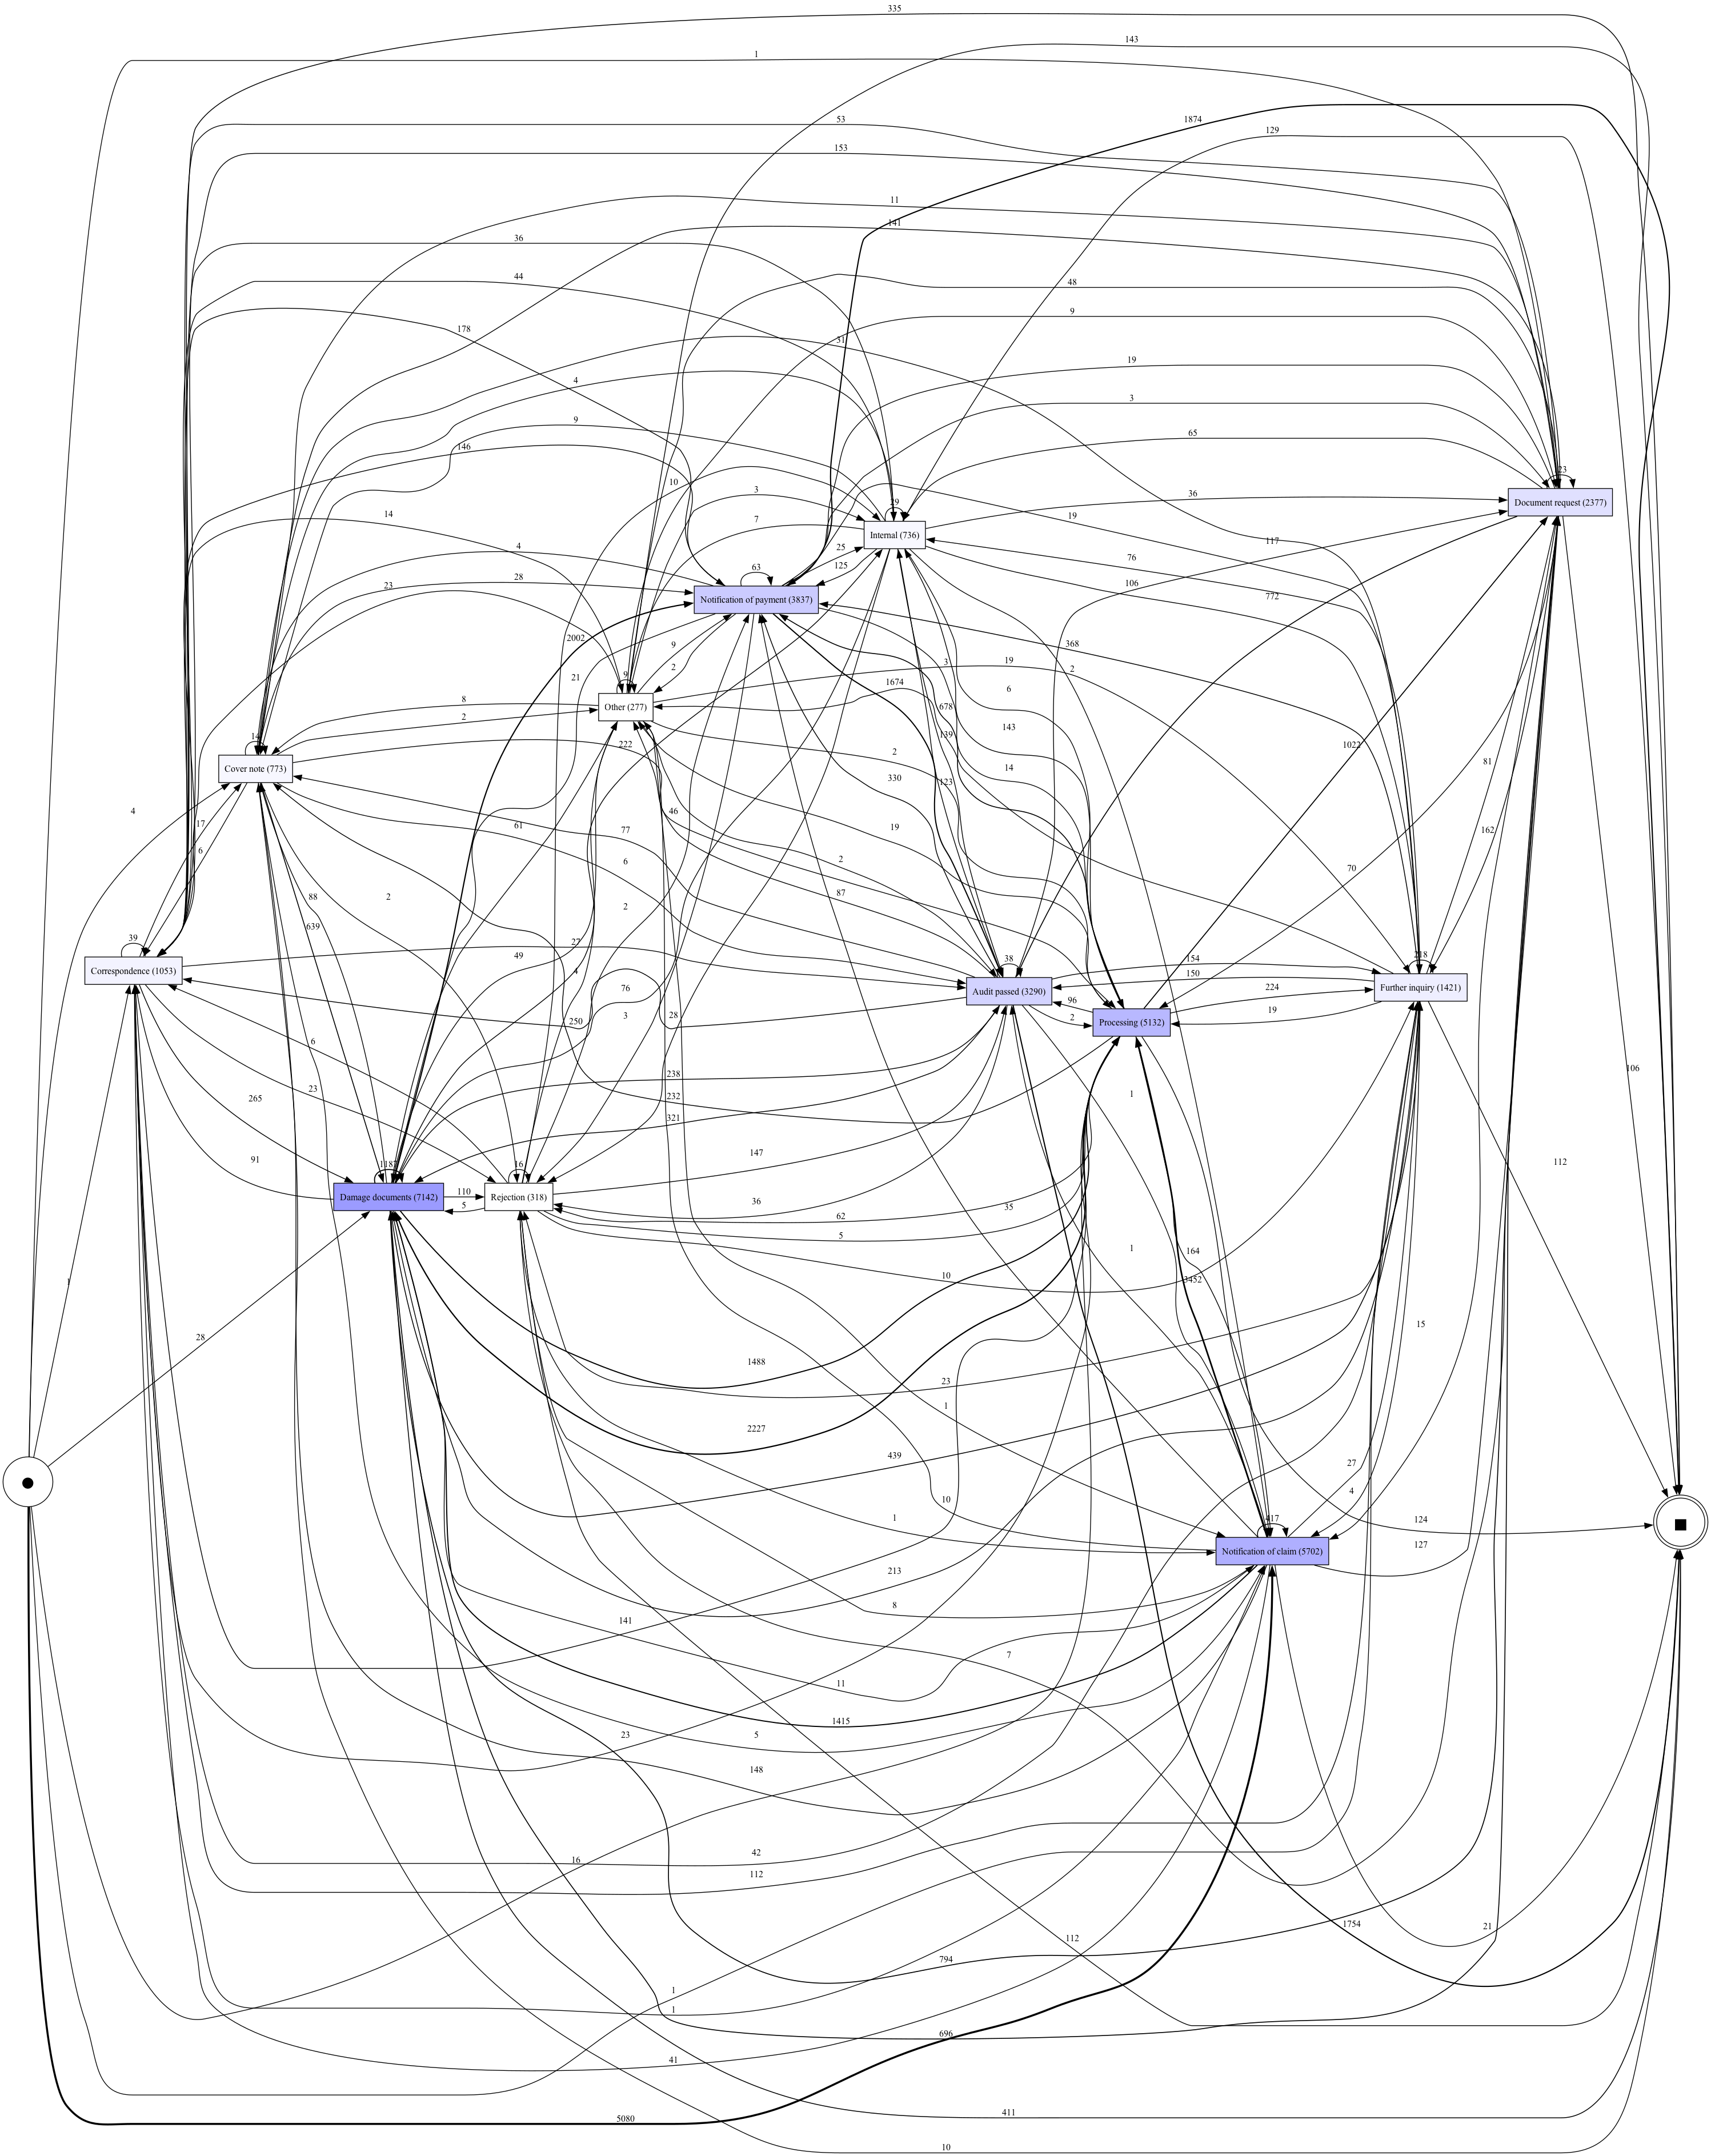

In [52]:
# Load the event log
event_log = pm4py.read_xes('process_log_car_insurance.xes')

# View DFG
dfg, start_activities, end_activities = pm4py.discover_dfg(event_log)
pm4py.view_dfg(dfg, start_activities, end_activities)

## **3. Generate JSON representation of the DFG**

The JSON is a list of objects containing:
    start_activity: source activity of the relation (not the case start)
    end_activity: target activity of the relation (not the case end)
    frequency: number of times this consecutive pair occurs in all cases
    performance: mean elapsed time between the pair's timestamps, in seconds

Performance includes any waiting between events; it is not a measure of
activity execution time alone. Only consecutive events within the same trace
(case) are connected. No artificial start or end nodes are added.

Events are processed in their stored XES order. This program expects events
in each trace to be in chronological order and reports an error otherwise.
For equal timestamps, the original event order is preserved.

In [53]:
%run xes_to_dfg.py process_log_car_insurance.xes Insurance_claims_2.json

Saved 137 DFG relations to Insurance_claims_2.json
[
  {
    "start_activity": "Notification of claim",
    "end_activity": "Processing",
    "frequency": 3452,
    "performance": 2080.704
  },
  {
    "start_activity": "Processing",
    "end_activity": "Damage documents",
    "frequency": 2227,
    "performance": 906019.932
  },
  {
    "start_activity": "Damage documents",
    "end_activity": "Notification of payment",
    "frequency": 2002,
    "performance": 8567.395
  },
  {
    "start_activity": "Notification of payment",
    "end_activity": "Audit passed",
    "frequency": 1674,
    "performance": 58758.565
  },
  {
    "start_activity": "Damage documents",
    "end_activity": "Processing",
    "frequency": 1488,
    "performance": 3031.409
  },
  {
    "start_activity": "Notification of claim",
    "end_activity": "Damage documents",
    "frequency": 1415,
    "performance": 16475.189
  },
  {
    "start_activity": "Damage documents",
    "end_activity": "Damage documents",
   

## **4. Setup the access to LLM and prompt the tasks**

### 4a. Ollama
Lessons learned: Ollama takes a lot of time to generate a response due to GPU power. It is recommended to use a more efficient LLM API.

In [5]:
payload = requests.post("http://localhost:11434/api/generate", json={"model":"llama3.1","prompt":"Who are you?", "stream":False})

print(json.loads(payload.text)["response"])

I'm an artificial intelligence model known as Llama. Llama stands for "Large Language Model Meta AI."


### 4b. OpenAI (GPT)
Model used: GPT-6.1-Sol

In [54]:
load_dotenv(".env")

txt_content = Path("prompt.txt").read_text(encoding="utf-8").replace("<domain>", "car insurance claim process")
json_content = Path("Insurance_claims_2.json").read_text(encoding="utf-8")

combined_prompt = txt_content + "\n" + json_content

response = OpenAI().chat.completions.create(model="gpt-6.1-sol", reasoning_effort="medium", messages=[{"role":"user","content":combined_prompt}]).choices[0].message.content

print(response + "\n\n")

from report_generator import save_redesign_excel
output_file = save_redesign_excel(response)
print(f"Saved to: {output_file.resolve()}")

## A. Data interpretation and limitations

- All supplied edges have activity labels, numeric frequencies, and numeric durations. Frequencies are positive integers; durations are positive. No missing or negative values are apparent.
- `performance` is explicitly defined as the **mean transition duration in seconds**. Therefore:
  \[
  \text{Accumulated transition duration}=\text{performance}\times\text{frequency}
  \]
  It must **not** be divided by frequency again.
- The timestamp lifecycle is unspecified: for example, whether durations connect completion timestamps, start timestamps, or another event timestamp. Consequently, transition durations cannot be separated into activity processing, waiting, external response, or administrative time.
- Frequencies count **edge occurrences, not unique claims**. Repeated visits may contribute multiple occurrences.
- The DFG does not establish complete case paths, concurrency, mandatory dependencies, or whether repeated events represent duplicat